Question 75. Create the residual plot and QQ plot for Q74's regression.

Original dataset:


,ID,Age,Income,Spending Score,Region,Category,Visits,Online Time,Purchase,Rating
0,1,22,25000,65,North,Grocery,5,12,Yes,4.2
1,2,35,55000,40,West,Electronics,2,8,No,3.8
2,3,28,32000,70,South,Clothing,6,15,Yes,4.5
3,4,45,75000,30,East,Grocery,3,6,No,3.5
4,5,30,60000,80,South,Electronics,7,18,Yes,4.8
5,6,26,40000,55,North,Clothing,4,10,Yes,4.1
6,7,38,50000,45,West,Grocery,3,9,No,3.9
7,8,29,45000,75,South,Electronics,6,16,Yes,4.6
8,9,50,80000,35,West,Clothing,2,5,No,3.6
9,10,33,52000,60,North,Grocery,5,11,Yes,4.3


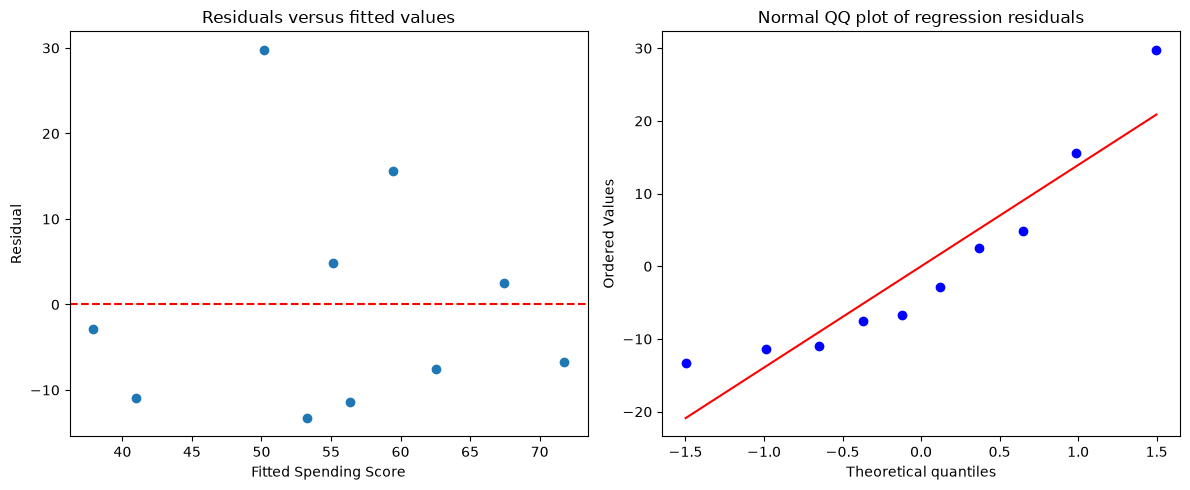

Saved question75_plot.png


In [1]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_PurchaseData.csv")
print("Original dataset:")
display(df)

# Step 3: Recreate Q74's regression model.
fit = stats.linregress(df["Income"], df["Spending Score"])

# Step 4: Calculate fitted scores and residuals (actual minus predicted).
predicted = fit.intercept + fit.slope * df["Income"]
residuals = df["Spending Score"] - predicted

# Step 5: Create two panels for regression diagnostics.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Step 6: Plot residuals against fitted scores, with zero as a reference line.
axes[0].scatter(predicted, residuals)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted Spending Score", ylabel="Residual", title="Residuals versus fitted values")

# Step 7: Compare residual quantiles with a normal distribution using a QQ plot.
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set(title="Normal QQ plot of regression residuals")

# Step 8: Save actual scores, fitted scores and residuals.
pd.DataFrame({"Income": df["Income"], "Actual": df["Spending Score"],
              "Fitted": predicted, "Residual": residuals}).to_csv("regression_residuals.csv", index=False)

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question75_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question75_plot.png")


Interpretation / method

The residual plot checks nonlinearity and changing spread; the QQ plot checks approximate residual normality, not normality of Income. Ten residuals cannot establish that regression assumptions hold.